### Diabetes is the fourth leading cause of death in the world and one of the most common endocrine disorders. According to studies, Type 2 diabetes kills thousands of people around the world every year and imposes huge costs on societies in the form of surgeries and other treatment programs, as well as controlling complications and disability. Therefore, predicting and early diagnosis of this disease can greatly help governments and patients.

### This dataset is the output of a Chinese research study conducted in 2016. It includes 1304 samples of patients who tested positive for diabetes, and the age of the participants ranges from 21 to 99 years old. The dataset was collected according to the indicators and standards of the World Health Organization, making it a reliable source for building diabetes diagnosis models. Researchers and healthcare professionals can use this dataset to train and test machine learning models to predict and diagnose diabetes in patients


source: https://datadryad.org/dataset/doi:10.5061/dryad.ft8750v

source:https://www.kaggle.com/datasets/pkdarabi/diabetes-dataset-with-18-features/data

---------------------------------------------------------------------------------------------------------------------------

In this study, I investigated the relationship between Body Mass Index (BMI) and the likelihood of having Type 2 Diabetes using a real-world healthcare dataset covering adults aged 20 and above.

I applied logistic regression analysis across different age groups to understand how BMI influences diabetes risk at various life stages.

### Key Finding:

Overall, a higher BMI was consistently associated with an increased probability of having diabetes.

The effect of BMI was statistically significant in most age groups, especially among middle-aged and older adults.

For example, in the 60–70 age group, every 1-point increase in BMI raised the odds of diabetes by approximately 6.9% (p = 0.009).

 These results align with published research, which confirms that obesity is a strong independent risk factor for Type 2 Diabetes, and this association is particularly evident in older populations.

## The model used logistic regression (via statsmodels) and showed good consistency with expectations in medical literature.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [171]:
df = pd.read_csv(r"C:\Users\Waseem\OneDrive\Desktop\diabetes.csv")
df

,Age,Gender,BMI,SBP,DBP,FPG,Chol,Tri,HDL,LDL,ALT,BUN,CCR,FFPG,smoking,drinking,family_histroy,Diabetes
0,26,1,20.1,119,81,5.80,4.36,0.86,0.90,2.43,12.0,5.40,63.8,5.40,3.000000,3.000000,0,0
1,40,1,17.7,97,54,4.60,3.70,1.02,1.50,2.04,9.2,3.70,70.3,4.10,1.000000,1.000000,0,0
2,40,2,19.7,85,53,5.30,5.87,1.29,1.75,3.37,10.1,4.10,61.1,4.85,3.000000,3.000000,0,0
3,43,1,23.1,111,71,4.50,4.05,0.74,1.27,2.60,36.5,4.38,73.4,5.30,2.000000,3.000000,0,0
4,36,1,26.5,130,82,5.54,6.69,3.49,0.91,3.64,69.3,3.86,67.5,5.53,3.000000,3.000000,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4298,54,1,23.4,126,75,6.82,5.00,1.50,1.24,2.98,8.0,3.50,77.0,6.70,1.000000,3.000000,0,1
4299,50,2,22.3,115,84,5.32,4.37,2.09,1.37,2.29,21.2,4.40,47.3,6.55,4.860753,4.860753,0,1
4300,67,1,24.6,138,81,4.85,3.89,1.38,1.14,2.17,18.1,4.73,70.6,6.80,3.000000,3.000000,0,1
4301,60,2,29.0,101,60,6.70,5.91,1.29,1.73,2.85,18.9,7.33,50.2,7.00,3.000000,3.000000,0,1


## Features of Dataset:

### Age 
### Gender (# Gender column:( 1 = Male) ( 2 = Female)
### DBP (Diastolic Blood Pressure)
### FPG (Fasting Plasma Glucose)
### FFPG (Final Fasting Plasma Glucose)
### Cholesterol Triglyceride HDL (High-Density Lipoprotein)
### LDL (Low-Density Lipoprotein)
### ALT (Alanine Aminotransferase)
### BUN (Blood urea nitrogen)
### CCR (Creatinine Clearance)
### Smoking Status: (1: Current Smoker, 2: Ever Smoker, 3: Never Smoker)
### Drinking Status: (1: Current Drinker, 2: Ever Drinker, 3: Never Drinker)
### Family History of Diabetes: (1: Yes, 0: No)
### Diabetes (0= No , 1= Yes))

In [123]:
df.rename(columns={
    'family_histroy': 'family_history',
    'Tri': 'Trig',
}, inplace=True)


In [142]:
df

,Age,Gender,BMI,SBP,DBP,FPG,Chol,Trig,HDL,LDL,ALT,BUN,CCR,FFPG,smoking,drinking,family_history,Diabetes
0,26,1,20.1,119,81,5.80,4.36,0.86,0.90,2.43,12.0,5.40,63.8,5.40,3.000000,3.000000,0,0
1,40,1,17.7,97,54,4.60,3.70,1.02,1.50,2.04,9.2,3.70,70.3,4.10,1.000000,1.000000,0,0
2,40,2,19.7,85,53,5.30,5.87,1.29,1.75,3.37,10.1,4.10,61.1,4.85,3.000000,3.000000,0,0
3,43,1,23.1,111,71,4.50,4.05,0.74,1.27,2.60,36.5,4.38,73.4,5.30,2.000000,3.000000,0,0
4,36,1,26.5,130,82,5.54,6.69,3.49,0.91,3.64,69.3,3.86,67.5,5.53,3.000000,3.000000,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4298,54,1,23.4,126,75,6.82,5.00,1.50,1.24,2.98,8.0,3.50,77.0,6.70,1.000000,3.000000,0,1
4299,50,2,22.3,115,84,5.32,4.37,2.09,1.37,2.29,21.2,4.40,47.3,6.55,4.860753,4.860753,0,1
4300,67,1,24.6,138,81,4.85,3.89,1.38,1.14,2.17,18.1,4.73,70.6,6.80,3.000000,3.000000,0,1
4301,60,2,29.0,101,60,6.70,5.91,1.29,1.73,2.85,18.9,7.33,50.2,7.00,3.000000,3.000000,0,1


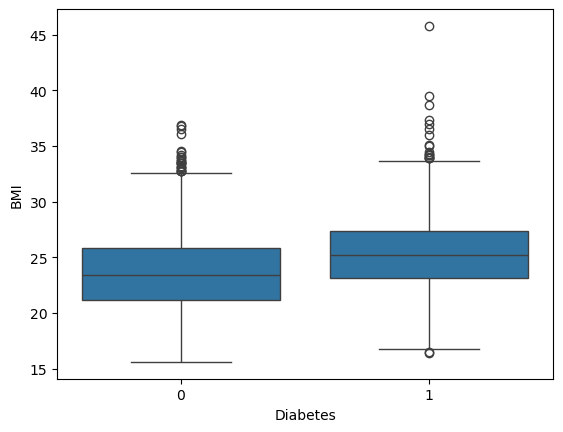

In [181]:
sns.boxplot(df,x='Diabetes',y='BMI');

<Axes: xlabel='BMI', ylabel='Count'>

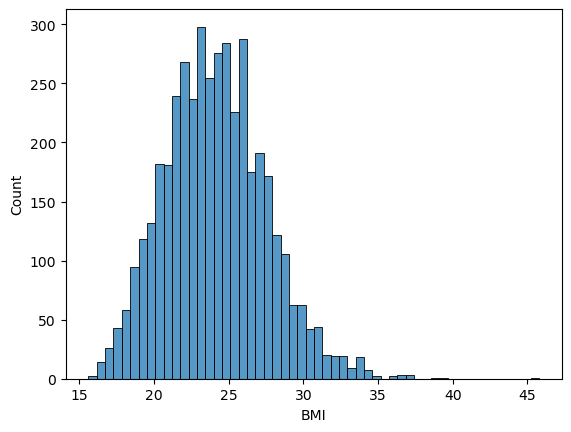

In [217]:
sns.histplot(df,x='BMI')




In [218]:
def check_normality(series, alpha=0.05):
    stat, p = shapiro(series.dropna())
    if p > alpha:
        print("✅ Data looks normally distributed (p > 0.05)")
    else:
        print("⚠️ Data does NOT look normally distributed (p <= 0.05)")


In [220]:
check_normality(df['BMI'], alpha=0.05)


⚠️ Data does NOT look normally distributed (p <= 0.05)


In [221]:
def summarize_categorical_distribution(df, column):
    counts = df[column].value_counts()
    percentages = df[column].value_counts(normalize=True) * 100
    summary = pd.DataFrame({'Count': counts, 'Percentage': percentages.round(2)})
    return summary

In [222]:
summarize_categorical_distribution(df, "BMI")

,Count,Percentage
BMI,,
23.50,62,1.44
23.40,59,1.37
26.00,59,1.37
24.80,56,1.30
23.80,55,1.28
...,...,...
20.57,1,0.02
32.60,1,0.02
28.34,1,0.02


In [155]:
df.duplicated().sum()

0

In [156]:
df.isnull().sum()

Age               0
Gender            0
BMI               0
SBP               0
DBP               0
FPG               0
Chol              0
Trig              0
HDL               0
LDL               0
ALT               0
BUN               0
CCR               0
FFPG              0
smoking           0
drinking          0
family_history    0
Diabetes          0
dtype: int64

In [182]:
df["Diabetes"].value_counts()

Diabetes
0    3000
1    1303
Name: count, dtype: int64

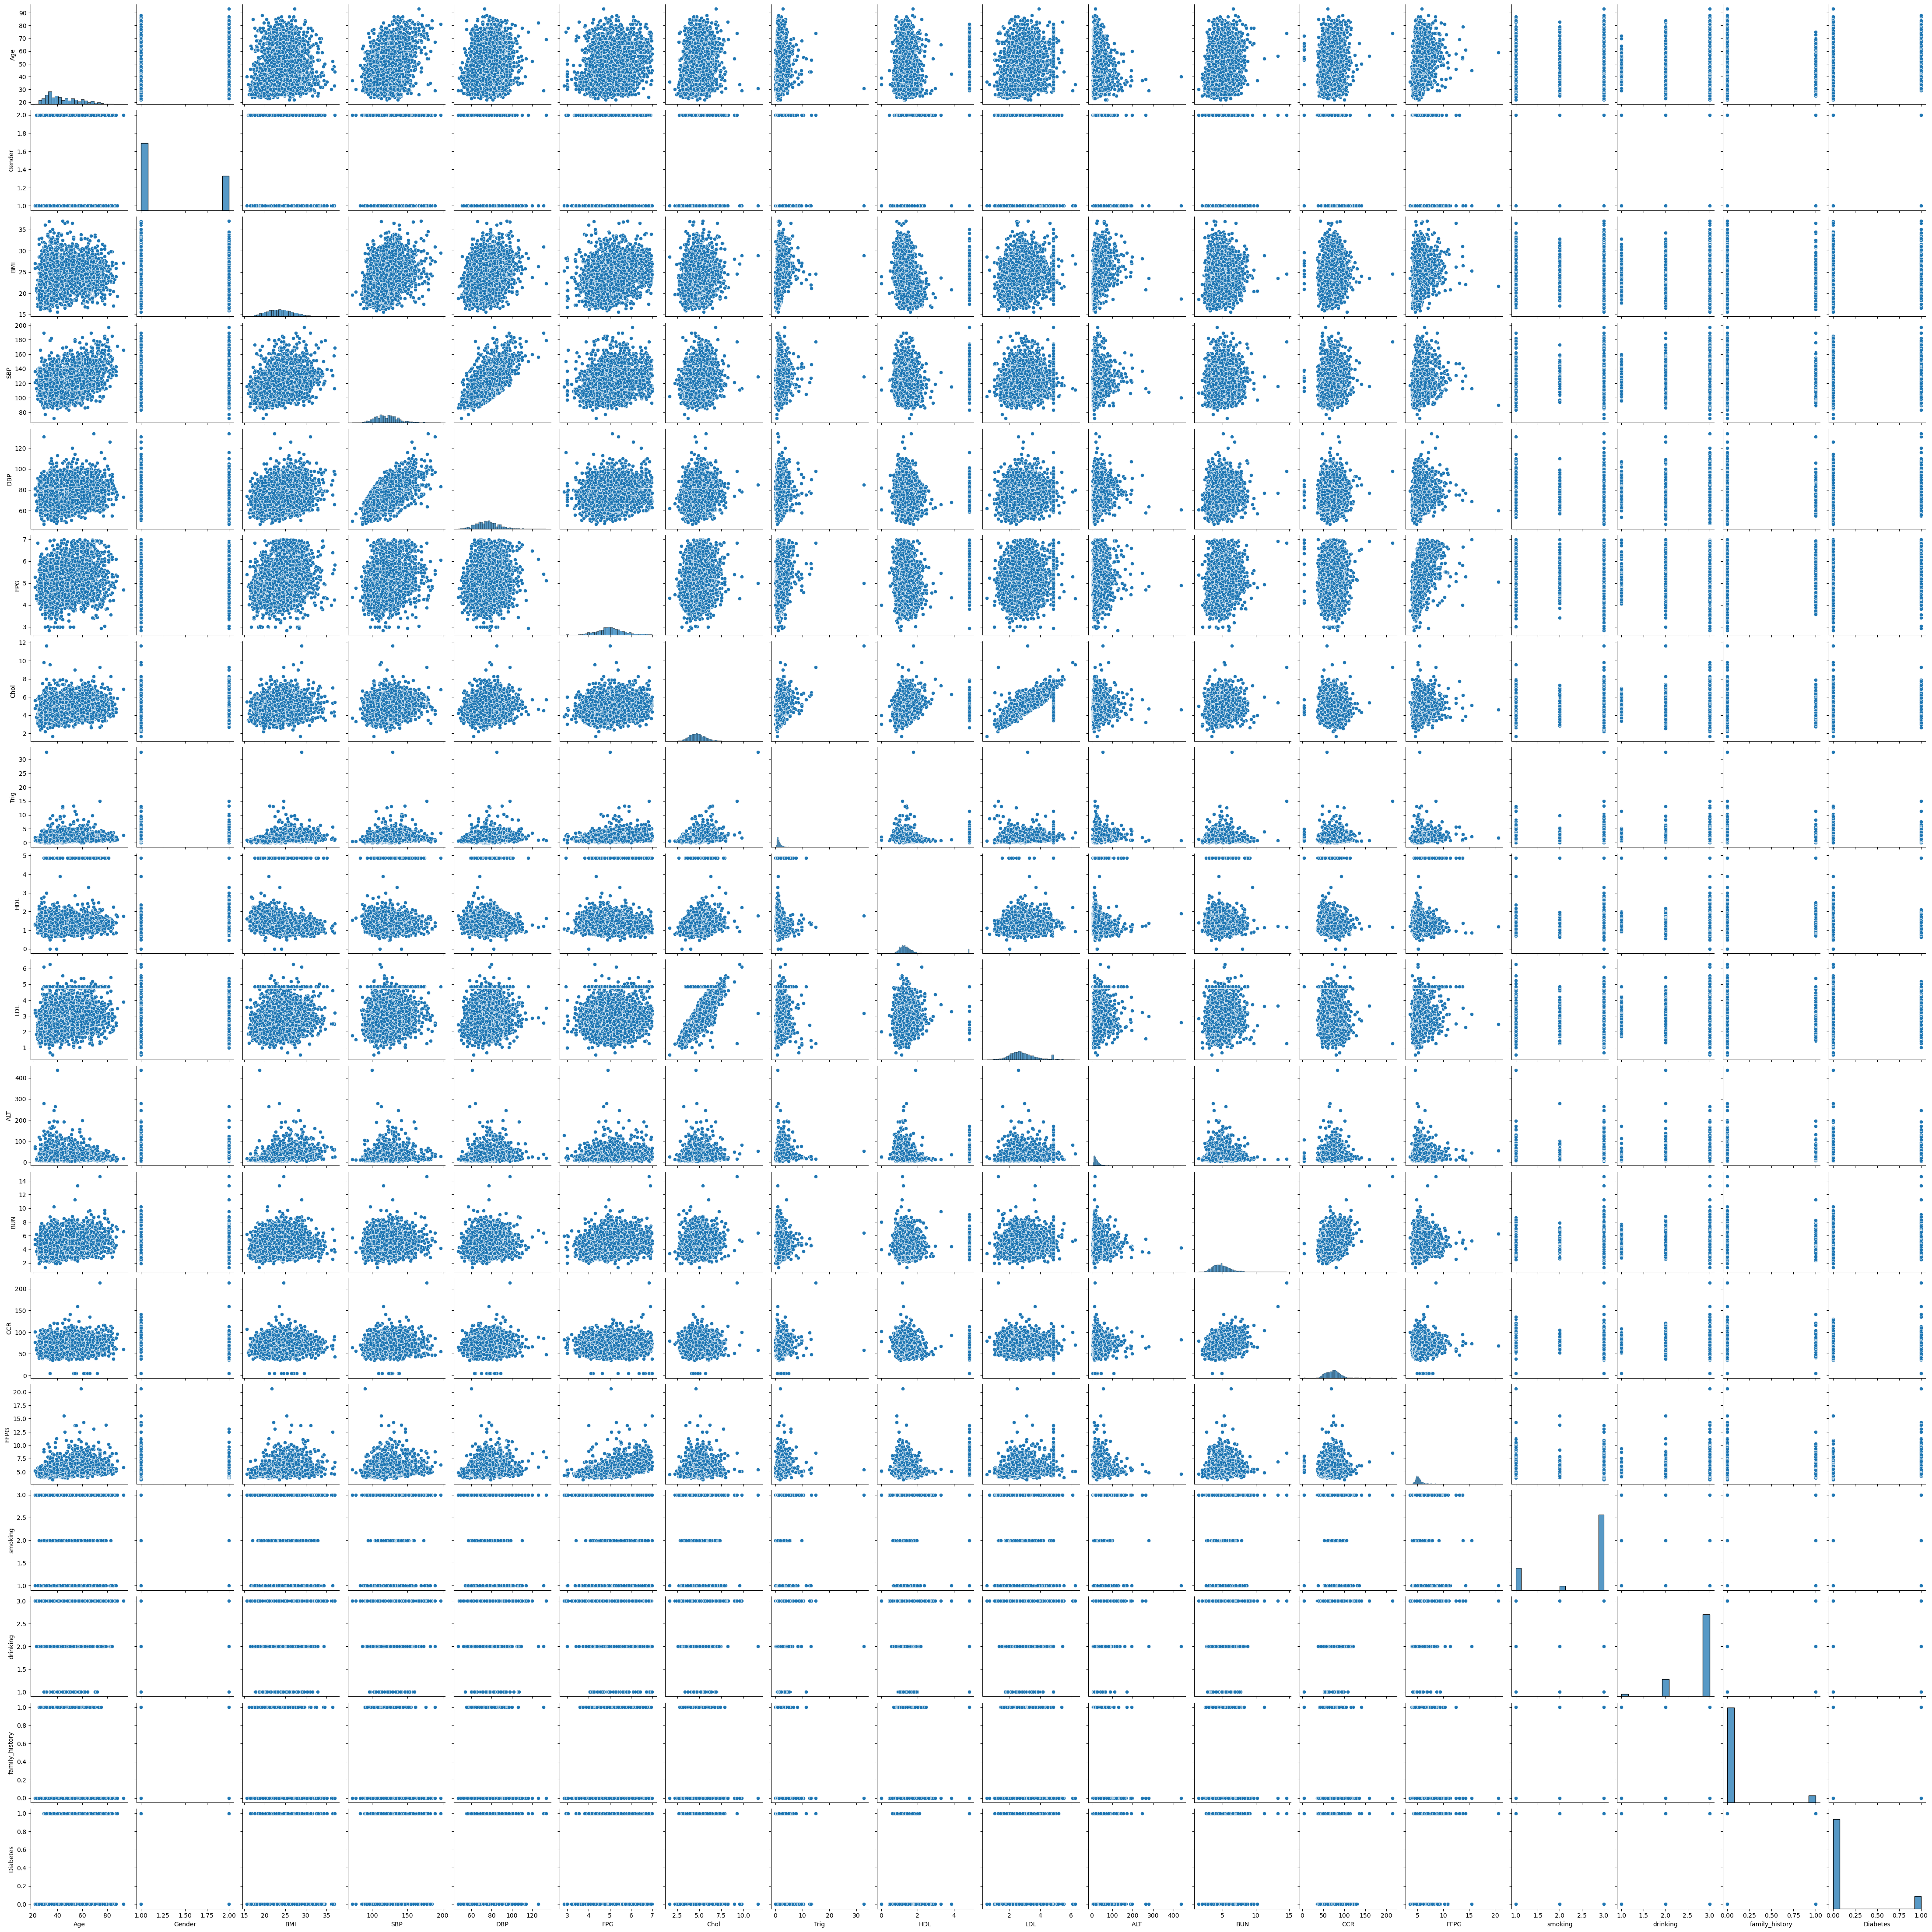

In [169]:
sns.pairplot(df)

In [183]:
df.corr()


,Age,Gender,BMI,SBP,DBP,FPG,Chol,Tri,HDL,LDL,ALT,BUN,CCR,FFPG,smoking,drinking,family_histroy,Diabetes
Age,1.000000,0.004783,0.232346,0.437992,0.230389,0.370798,0.242679,0.163353,0.213133,0.295938,-0.036210,0.276961,0.023667,0.359268,0.244430,0.370963,-0.037955,0.521380
Gender,0.004783,1.000000,-0.252456,-0.125792,-0.186603,-0.073297,0.055566,-0.155444,0.072716,0.001364,-0.235779,-0.147157,-0.602743,-0.049288,0.261566,0.158599,0.066452,0.007251
BMI,0.232346,-0.252456,1.000000,0.328772,0.318889,0.270508,0.173834,0.315455,0.047260,0.201447,0.343488,0.107482,0.155089,0.247893,0.036824,0.105632,0.013928,0.236583
SBP,0.437992,-0.125792,0.328772,1.000000,0.651806,0.263391,0.164950,0.196480,0.089887,0.167468,0.111913,0.143541,0.088885,0.221215,0.139364,0.180866,-0.052285,0.282476
DBP,0.230389,-0.186603,0.318889,0.651806,1.000000,0.178995,0.141619,0.194973,0.048761,0.146217,0.158603,0.087696,0.103241,0.167874,0.037215,0.084919,-0.012258,0.169963
FPG,0.370798,-0.073297,0.270508,0.263391,0.178995,1.000000,0.163499,0.212294,0.201780,0.239304,0.113730,0.169327,0.039803,0.473931,0.278685,0.348008,0.001427,0.515342
Chol,0.242679,0.055566,0.173834,0.164950,0.141619,0.163499,1.000000,0.335038,0.114105,0.651530,0.151360,0.129534,-0.004502,0.106131,0.038658,0.075083,-0.002684,0.124310
Tri,0.163353,-0.155444,0.315455,0.196480,0.194973,0.212294,0.335038,1.000000,0.048405,0.158445,0.245089,0.044594,0.090810,0.165935,-0.004733,0.055889,0.012511,0.169151
HDL,0.213133,0.072716,0.047260,0.089887,0.048761,0.201780,0.114105,0.048405,1.000000,0.655013,0.005198,0.056119,-0.147407,0.244480,0.262487,0.295627,0.039533,0.453618
LDL,0.295938,0.001364,0.201447,0.167468,0.146217,0.239304,0.651530,0.158445,0.655013,1.000000,0.120501,0.129122,-0.061717,0.242597,0.176180,0.254001,0.026949,0.386235


In [184]:
def show_correlation_matrix(df):
    corr = df.corr()
    print("\nCorrelation Matrix:")
    print(corr.round(2))
    plt.figure(figsize=(8, 6))
    sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.show()



Correlation Matrix:
                 Age  Gender   BMI   SBP   DBP   FPG  Chol   Tri   HDL   LDL  \
Age             1.00    0.00  0.23  0.44  0.23  0.37  0.24  0.16  0.21  0.30   
Gender          0.00    1.00 -0.25 -0.13 -0.19 -0.07  0.06 -0.16  0.07  0.00   
BMI             0.23   -0.25  1.00  0.33  0.32  0.27  0.17  0.32  0.05  0.20   
SBP             0.44   -0.13  0.33  1.00  0.65  0.26  0.16  0.20  0.09  0.17   
DBP             0.23   -0.19  0.32  0.65  1.00  0.18  0.14  0.19  0.05  0.15   
FPG             0.37   -0.07  0.27  0.26  0.18  1.00  0.16  0.21  0.20  0.24   
Chol            0.24    0.06  0.17  0.16  0.14  0.16  1.00  0.34  0.11  0.65   
Tri             0.16   -0.16  0.32  0.20  0.19  0.21  0.34  1.00  0.05  0.16   
HDL             0.21    0.07  0.05  0.09  0.05  0.20  0.11  0.05  1.00  0.66   
LDL             0.30    0.00  0.20  0.17  0.15  0.24  0.65  0.16  0.66  1.00   
ALT            -0.04   -0.24  0.34  0.11  0.16  0.11  0.15  0.25  0.01  0.12   
BUN             0.2

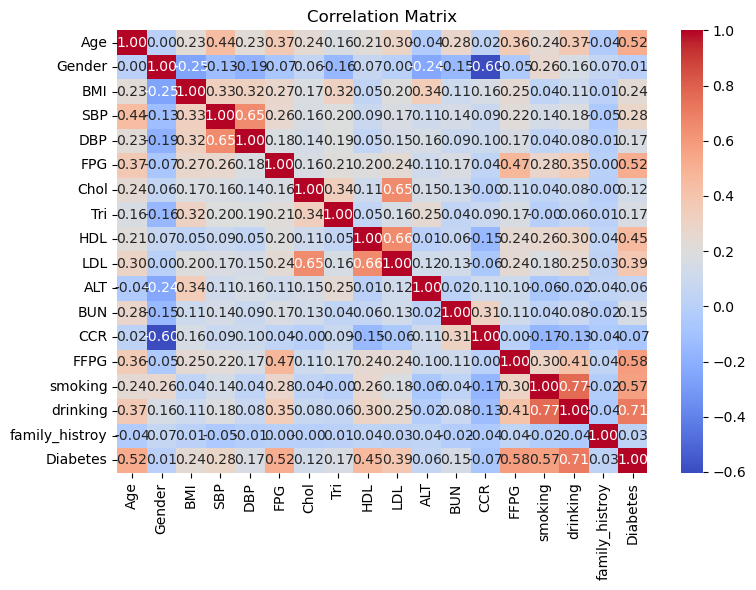

In [185]:
show_correlation_matrix(df);

In [190]:
from scipy.stats import (
    ttest_ind, ttest_1samp, ttest_rel,
    f_oneway, chi2_contingency, shapiro, probplot)

In [196]:
def t_test_independent_from_df(df, col, group_col, group1_val, group2_val, alpha=0.05):
    g1 = df[df[group_col] == group1_val][col].dropna()
    g2 = df[df[group_col] == group2_val][col].dropna()
    t_stat, p_val = ttest_ind(g1, g2)
    print(f"Independent T-Test between {group1_val} and {group2_val} on '{col}':")
    print(f"T = {t_stat:.4f}, P = {p_val:.4f}")
    print("Significant difference" if p_val < alpha else "❌ No significant difference")

In [197]:
t_test_independent_from_df(df, col='BMI', group_col='Diabetes', group1_val=1, group2_val=0)


Independent T-Test between 1 and 0 on 'BMI':
T = 15.9689, P = 0.0000
Significant difference


In [207]:
bins = [20, 30, 40, 50, 60, 70, 150]  # آخر حد كبير يشمل كل الأعمار >70
labels = ['20–30', '30–40', '40–50', '50–60', '60–70', '70+']

df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=False)


In [213]:

df.groupby('Age_Group', observed=True)['Diabetes'].mean()


Age_Group
20–30    0.025424
30–40    0.060302
40–50    0.177494
50–60    0.480192
60–70    0.582840
70+      0.716146
Name: Diabetes, dtype: float64

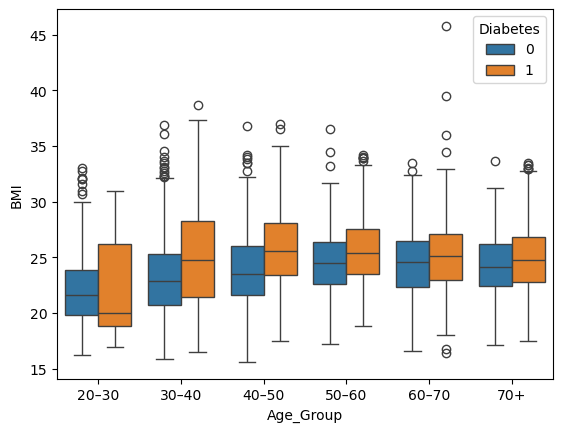

In [215]:

sns.boxplot(x='Age_Group', y='BMI', hue='Diabetes', data=df);


In [210]:
for group in df['Age_Group'].unique():
    subset = df[df['Age_Group'] == group]
    model = sm.Logit(subset['Diabetes'], sm.add_constant(subset['BMI'])).fit()
    print(f"==== Age Group: {group} ====")
    print(model.summary())


Optimization terminated successfully.
         Current function value: 0.118415
         Iterations 8
==== Age Group: 20–30 ====
                           Logit Regression Results                           
Dep. Variable:               Diabetes   No. Observations:                  354
Model:                          Logit   Df Residuals:                      352
Method:                           MLE   Df Model:                            1
Date:                Sun, 01 Jun 2025   Pseudo R-squ.:               0.0003422
Time:                        00:20:17   Log-Likelihood:                -41.919
converged:                       True   LL-Null:                       -41.933
Covariance Type:            nonrobust   LLR p-value:                    0.8655
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -4.0227      2.242     -1.794      0.073      -8.416       0.371
BM